# In-service EV voltage snapshots with per-cell fault labels

This notebook lists the voltage snapshots in the Zenodo release, loads one snapshot as released, and plots its 14 cell voltages with the cell labels. It makes no diagnosis.

## 1. Released units

This step lists what `systems('li2026_evfault')` reports for the release.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd

ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'fielddata').exists())
sys.path.insert(0, str(ROOT))
from fielddata import load, systems

released = systems('li2026_evfault')
display(released)

,window,samples,cells,faulty_cells,codes
0,0,50,14,1,14:1
1,1,50,14,1,14:1
2,2,50,14,0,
3,3,50,14,0,
4,4,50,14,1,14:1
...,...,...,...,...,...
3402,3402,50,14,0,
3403,3403,50,14,0,
3404,3404,50,14,0,
3405,3405,50,14,0,


Each row is one released voltage snapshot, numbered 0 to 3,406 with none missing, with the cells its label file marks as faulty and their codes (cell:code). The readme says 3,408 segments from 99 in-service EVs, but the release has no vehicle identifiers, so snapshots cannot be grouped by vehicle. 2,236 snapshots have at least one labelled cell. The layout claims here cover every snapshot and are saved in `reports/candidates/li2026_evfault/layout.txt` and `li2026_evfault_profile.csv`.

## 2. One unit as released

This step loads one unit with the default `clean=False`, so every value is as released.

In [2]:
frame = load('li2026_evfault', window=2243)
print(frame.shape)
display(frame.head())

(50, 16)


,window,sample,V 1,V 2,V 3,V 4,V 5,V 6,V 7,V 8,V 9,V 10,V 11,V 12,V 13,V 14
0,2243,0,4155.0,4158.0,4158.0,4165.0,4164.0,4160.0,3943.0,4168.0,4166.0,4025.0,4170.0,4174.0,4173.0,4156.0
1,2243,1,4156.0,4158.0,4159.0,4166.0,4165.0,4162.0,3944.0,4168.0,4167.0,4026.0,4172.0,4174.0,4175.0,4157.0
2,2243,2,4156.0,4160.0,4161.0,4167.0,4165.0,4165.0,3945.0,4170.0,4168.0,4027.0,4173.0,4176.0,4176.0,4158.0
3,2243,3,4158.0,4162.0,4161.0,4169.0,4167.0,4166.0,3945.0,4171.0,4170.0,4028.0,4174.0,4176.0,4177.0,4159.0
4,2243,4,4158.0,4163.0,4162.0,4170.0,4169.0,4167.0,3947.0,4172.0,4171.0,4029.0,4175.0,4177.0,4178.0,4160.0


Snapshot 2243 has 50 rows and the 14 cell voltages in mV, as released, with the loader's `window` and `sample` columns added. Every snapshot has this shape. Samples are 10 s apart by the paper's stated 0.1 Hz. The release has no time, current or temperature columns.

## 3. Signal ranges

This step summarises a few signals of the loaded unit.

In [3]:
display(frame[['V 1', 'V 10', 'V 14']].describe().T)

,count,mean,std,min,25%,50%,75%,max
V 1,50.0,4160.44,10.694572,4148.0,4150.5,4157.5,4168.75,4182.0
V 10,50.0,4028.26,8.968903,4017.0,4020.0,4027.0,4035.75,4046.0
V 14,50.0,4158.76,12.625792,4143.0,4147.0,4157.5,4168.00,4184.0


These ranges are raw values for snapshot 2243, as released, before any cleaning. Cell 1 ranges from 4,148 to 4,182 mV, cell 10 from 4,017 to 4,046 mV and cell 14 from 4,143 to 4,184 mV. Across all snapshots the raw voltages run from 3,554 to 4,202 mV, as `layout.txt` records.

## 4. A first look

This step plots one signal to show the shape of the data.

   cell  code label
6     7   4.0   ISC
9    10   4.0   ISC


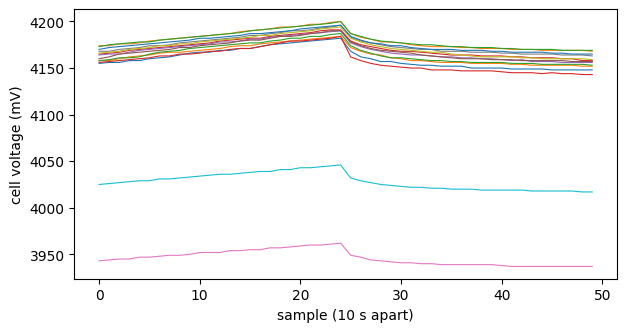

In [4]:
from fielddata.loaders import li2026_evfault
print(li2026_evfault.labels(2243).query('code > 0')[['cell', 'code', 'label']])
ax = frame.drop(columns=['window', 'sample']).plot(figsize=(7, 3.5), lw=0.8, legend=False)
ax.set_xlabel('sample (10 s apart)')
ax.set_ylabel('cell voltage (mV)')
plt.show()

The labels mark cells 7 and 10 with code 4, internal short circuit by the readme's order. In the plot, these two cells sit about 135 and 215 mV below the other twelve cells throughout, raw. All cells rise until sample 24 and then drop, which is where charging ends in most snapshots. The schema note explains where the code order comes from.